<a href="https://colab.research.google.com/github/vera2005/MLCV_course1/blob/main/Lesson4/Lesson_4FULL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Загружаем датасет
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = ['Футболка', 'Брюки', 'Свитер', 'Платье', 'Пальто',
               'Сандалии', 'Рубашка', 'Кроссовки', 'Сумка', 'Ботинки']

# Нормализация: пиксели 0..255 -> 0..1
x_train = x_train / 255.0
x_test = x_test / 255.0

# Добавляем канал: (28, 28) -> (28, 28, 1)
x_train = x_train[..., None]
x_test = x_test[..., None]

print('Обучающая выборка:', x_train.shape)
print('Тестовая выборка:  ', x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Обучающая выборка: (60000, 28, 28, 1)
Тестовая выборка:   (10000, 28, 28, 1)


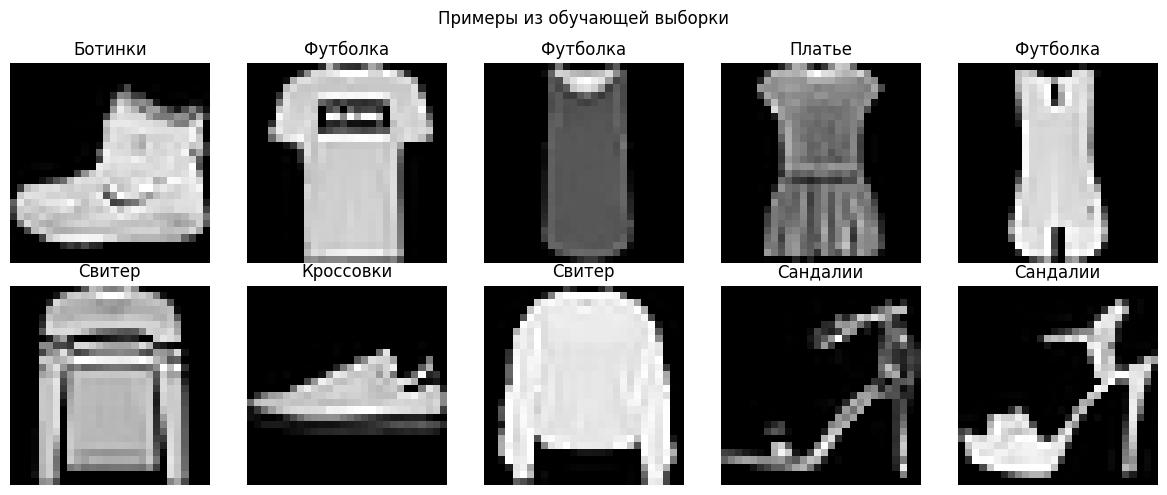

In [ ]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.suptitle('Примеры из обучающей выборки')
plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Свёрточный блок 1
    layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Свёрточный блок 2
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Классификатор
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,866 (413.54 KB)

 Trainable params: 105,866 (413.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(x_train, y_train,
                    epochs=5,
                    validation_split=0.1,
                    batch_size=64)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 39s 44ms/step - accuracy: 0.8251 - loss: 0.4906 - val_accuracy: 0.8652 - val_loss: 0.3789
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 36s 42ms/step - accuracy: 0.8832 - loss: 0.3256 - val_accuracy: 0.8847 - val_loss: 0.3236
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 36s 42ms/step - accuracy: 0.8978 - loss: 0.2837 - val_accuracy: 0.8947 - val_loss: 0.2972
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 44ms/step - accuracy: 0.9082 - loss: 0.2555 - val_accuracy: 0.8977 - val_loss: 0.2835
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 35s 41ms/step - accuracy: 0.9158 - loss: 0.2339 - val_accuracy: 0.9028 - val_loss: 0.2723


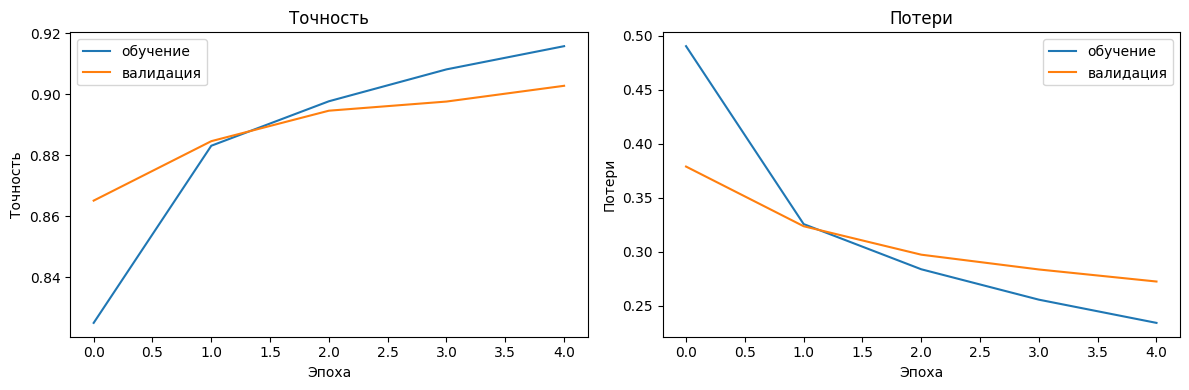

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='обучение')
plt.plot(history.history['val_accuracy'], label='валидация')
plt.xlabel('Эпоха'); plt.ylabel('Точность')
plt.legend(); plt.title('Точность')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='обучение')
plt.plot(history.history['val_loss'], label='валидация')
plt.xlabel('Эпоха'); plt.ylabel('Потери')
plt.legend(); plt.title('Потери')

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f'Точность на тестовой выборке: {test_acc:.4f}')

Точность на тестовой выборке: 0.8974


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step


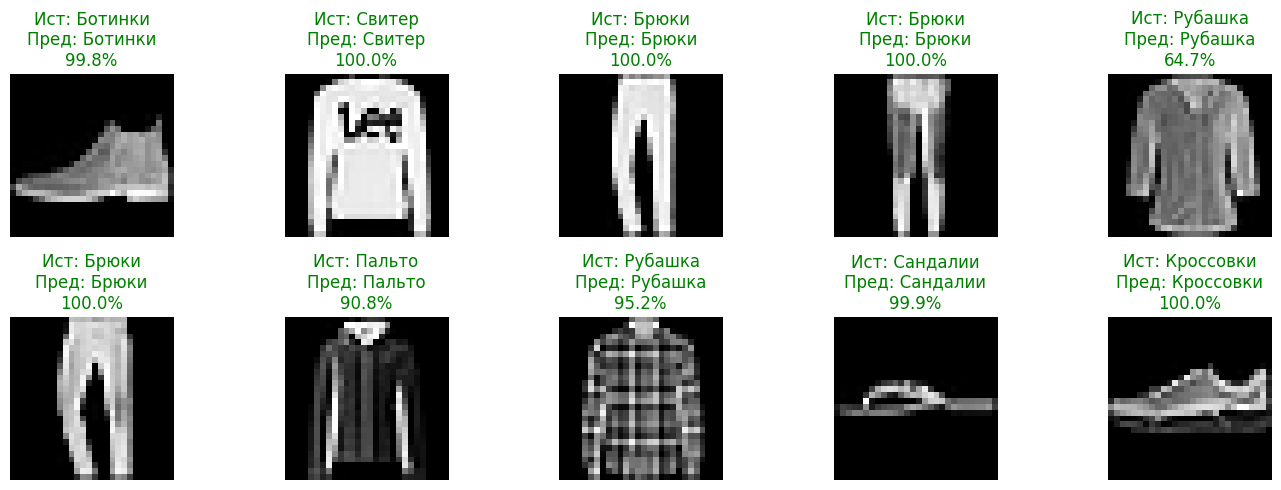

In [ ]:
# Предсказания для первых 10 изображений теста
probs = model.predict(x_test[:10])          # вероятности по 10 классам
preds = np.argmax(probs, axis=1)            # выбранный класс
confs = np.max(probs, axis=1)               # уверенность модели

plt.figure(figsize=(14, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    true_label = class_names[y_test[i]]
    pred_label = class_names[preds[i]]
    color = 'green' if preds[i] == y_test[i] else 'red'
    plt.title(f'Ист: {true_label}\nПред: {pred_label}\n{confs[i]*100:.1f}%', color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()